<center><h1>Linarez_Isabella_HW3</h1></center>
<br>
<br>

Name: Isabella Linarez
<br>
Github Username: isalinarez927
<br>
USC ID: 7543590784

## 1. Time Series Classification Part 1: Feature Creation/Extraction

### (a) Download Data

Package imports

In [28]:
import numpy as np
import statistics
from scipy import stats
import pandas as pd
import matplotlib.pyplot as plt
import os

Get the AReM Data Set

In [29]:

root = "Data/AReM"
cols = ["time", "avg_rss12", "var_rss12", "avg_rss13",
        "var_rss13", "avg_rss23", "var_rss23"]
records = []

for folder in sorted(os.listdir(root)):
    folder_path = os.path.join(root, folder)
    if not os.path.isdir(folder_path):
        continue
    for fname in sorted(os.listdir(folder_path)):
        if not fname.endswith(".csv"):
            continue
        df = pd.read_csv(os.path.join(folder_path, fname),
                         comment="#", header=None, names=cols,
                         sep=r"[,\s]+", engine="python", usecols=range(7))
        # some files were space-delimited and sep=r"[,\s]+" handles both
        num = int(fname.replace("dataset", "").replace(".csv", ""))
        records.append({"label": folder, "num": num, "df": df})


### (b) Test and Train Data

In [30]:
train, test = [], []
for r in records:
    if r["label"].startswith("bending"):
        is_test = r["num"] in range(1,3)      # check r["num"] against bending's test numbers
    else:
        is_test = r["num"] in range(1,4)      # check r["num"] against bending's test numbers
    (test if is_test else train).append(r)

print(len(train), len(test))

69 19


### (c) Feature Extraction

#### i. Research

 Basic statistical features such as mean, median, variance, standard deviation, skewness (asymmetry), and kurtosis (how heavy the tails are / how peaked the distribution).

 Extremes and Range Metrics such as minimum, maximum, peak-to-peak range, and quantiles/percentiles

 Energy / magnitude metrics such as RMS (root mean square) and signal energy (sum of squared values).


Temporal behavior such as autocorrelation, zero-crossing or mean-crossing rate, mean absolute change between consecutive points, and slope/trend

#### ii. Extraction

In [31]:
def extract_features(df):
    signals = df.drop(columns="time")
    signals.columns = [str(i) for i in range(1, 7)]
    stats = signals.agg(["min", "max", "mean", "median", "std",
                         lambda s: s.quantile(0.25),
                         lambda s: s.quantile(0.75)])

    stats.index = ["min", "max", "mean", "median", "std", "1st_quart", "3rd_quart"]
    
    flattened = stats.unstack()
    
    flattened.index = [f"{stat}{col}" for col, stat in flattened.index]
    
    return pd.DataFrame([flattened])

featureTable = []

for i in range(len(records)):
    feat = extract_features(records[i]["df"])
    feat["label"] = records[i]["label"]
    feat["split"] = "test" if records[i] in test else "train"
    featureTable.append(feat)

features = pd.concat(featureTable, ignore_index=True)
features.index = range(1, 89)
features.index.name = "Instance"
features
# print(features["label"].value_counts())
# print(features["split"].value_counts())

,min1,max1,mean1,median1,std1,1st_quart1,3rd_quart1,min2,max2,mean2,median2,std2,1st_quart2,3rd_quart2,min3,max3,mean3,median3,std3,1st_quart3,3rd_quart3,min4,max4,mean4,median4,std4,1st_quart4,3rd_quart4,min5,max5,mean5,median5,std5,1st_quart5,3rd_quart5,min6,max6,mean6,median6,std6,1st_quart6,3rd_quart6,label,split
Instance,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1,37.25,45.00,40.624792,40.500,1.476967,39.25,42.0000,0.0,1.30,0.358604,0.430,0.322605,0.00,0.5000,4.00,29.50,19.040937,19.250,4.462952,16.00,23.2500,0.0,7.23,0.832542,0.500,0.965659,0.0000,1.1200,27.25,38.25,34.311292,35.00,2.188449,33.0000,36.00,0.0,1.92,0.570583,0.430,0.582915,0.00,1.3000,bending1,test
2,38.00,45.67,42.812812,42.500,1.435550,42.00,43.6700,0.0,1.22,0.372437,0.470,0.289158,0.00,0.5000,2.00,29.50,20.096979,21.000,3.893737,19.00,22.2500,0.0,5.76,0.876438,0.500,1.047259,0.0000,1.1450,27.67,38.50,33.024583,33.00,1.995255,32.0000,34.50,0.0,3.11,0.571083,0.430,0.601010,0.00,1.3000,bending1,test
3,35.00,47.40,43.954500,44.330,1.558835,43.00,45.0000,0.0,1.70,0.426250,0.470,0.338690,0.00,0.5000,6.50,29.75,22.122354,23.000,3.030943,19.75,24.0000,0.0,4.44,0.497312,0.430,0.550657,0.0000,0.8300,29.00,38.50,35.588458,36.00,1.999604,35.3625,36.50,0.0,1.79,0.493292,0.430,0.513506,0.00,0.9400,bending1,train
4,33.00,47.75,42.179812,43.500,3.670666,39.15,45.0000,0.0,3.00,0.696042,0.500,0.630860,0.00,1.1200,8.50,30.00,22.183625,23.000,3.810469,20.50,24.3725,0.0,5.15,0.989917,0.830,0.953730,0.4300,1.3000,20.00,38.67,33.493917,35.00,3.849448,30.4575,36.33,0.0,2.18,0.613521,0.500,0.524317,0.00,1.0000,bending1,train
5,33.00,45.75,41.678063,41.750,2.243490,41.33,42.7500,0.0,2.83,0.535979,0.500,0.405469,0.43,0.7100,3.00,28.25,19.006563,19.125,4.087107,16.50,22.0625,0.0,6.42,0.841875,0.500,0.928801,0.4300,1.1200,23.67,37.50,29.857083,30.00,2.411026,28.4575,31.25,0.0,1.79,0.383292,0.430,0.389164,0.00,0.5000,bending1,train
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
84,20.75,46.25,34.763333,35.290,4.742208,31.67,38.2500,0.0,12.68,4.223792,3.900,2.278004,2.49,5.7225,5.00,23.75,15.239021,15.330,2.920829,13.50,17.2500,0.0,9.20,3.207062,3.000,1.590472,2.0500,4.1950,6.00,25.50,16.299563,16.25,3.174681,14.2500,18.33,0.0,9.39,3.288271,3.270,1.647528,2.05,4.3050,walking,train
85,21.50,51.00,34.935812,35.500,4.645944,32.00,38.0625,0.0,12.21,4.115750,3.845,2.335243,2.35,5.6250,6.50,23.33,15.524521,15.500,2.900248,13.33,17.6700,0.0,9.09,3.092792,2.870,1.503446,2.0575,3.8400,6.33,25.00,15.997229,16.25,3.192058,14.2375,18.25,0.0,10.21,3.280021,3.015,1.700918,2.12,4.5000,walking,train
86,18.33,47.67,34.333042,34.750,4.948770,31.25,38.0000,0.0,12.48,4.396958,3.900,2.568680,2.49,5.7450,7.67,23.33,15.562896,15.500,2.967741,13.67,17.5000,0.0,9.01,3.198313,2.930,1.676271,2.0500,4.2450,6.67,24.00,15.864437,16.00,3.000493,13.7500,18.00,0.0,8.01,3.261583,2.980,1.617290,2.05,4.3200,walking,train


#### iii. Standard Deviation

In [32]:
B = 1000
rng = np.random.default_rng(42)
results = []

feat_cols = features.columns.drop(["label", "split"])
for col in feat_cols:
    x = features[col].values
    point_std = statistics.stdev(x)                          
    boot_stds = []
    for i in range(B):
        sample = rng.choice(x, size=len(x), replace=True)
        boot_stds.append(np.std(sample, ddof=1))
    lower, upper = np.percentile(boot_stds, [5, 95])
    results.append({"feature": col, "std": point_std,
                    "CI_lower": lower, "CI_upper": upper})

ci_table = pd.DataFrame(results)
ci_table

,feature,std,CI_lower,CI_upper
0,min1,9.569975,8.194325,10.848390
1,max1,4.394362,3.328131,5.267411
2,mean1,5.335718,4.666422,5.871471
3,median1,5.440054,4.800392,5.977818
4,std1,1.772153,1.562906,1.948855
5,1st_quart1,6.153590,5.525727,6.665116
6,3rd_quart1,5.138925,4.341983,5.876490
7,min2,0.000000,0.000000,0.000000
8,max2,5.062729,4.587641,5.411003
9,mean2,1.574164,1.397205,1.705741


I resampled the 88 values with replacement 1000 times, computed the std of each resample, and took the 5th and 95th percentiles of those 1000 values as the lower and upper bounds.

 min2, min4, and min6 have a std of 0 (and a CI of [0, 0]) because these are variance series, and every recording hits a minimum variance of 0, so there is no spread to measure.

The histogram below shows the bootstrap distribution for 3rd_quart6. It is slightly skewed rather than perfectly normal

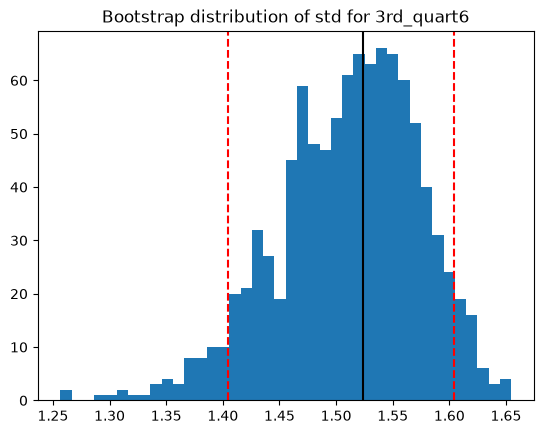

In [33]:
plt.hist(boot_stds, bins=40)
plt.title("Bootstrap distribution of std for 3rd_quart6")
plt.axvline(lower, color="red", linestyle="--")
plt.axvline(upper, color="red", linestyle="--")
plt.axvline(point_std, color="black")
plt.show()

#### iv. Select Features

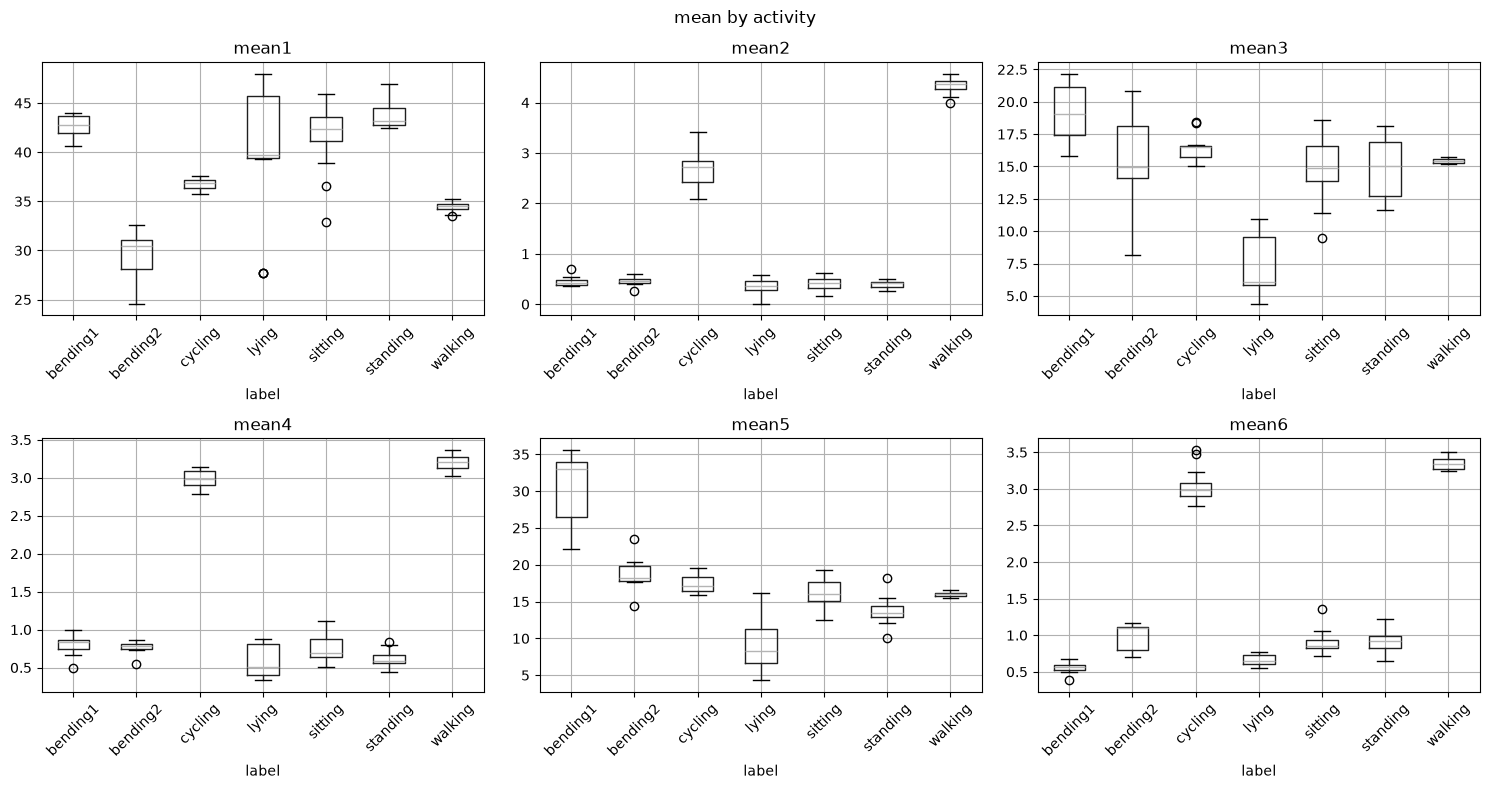

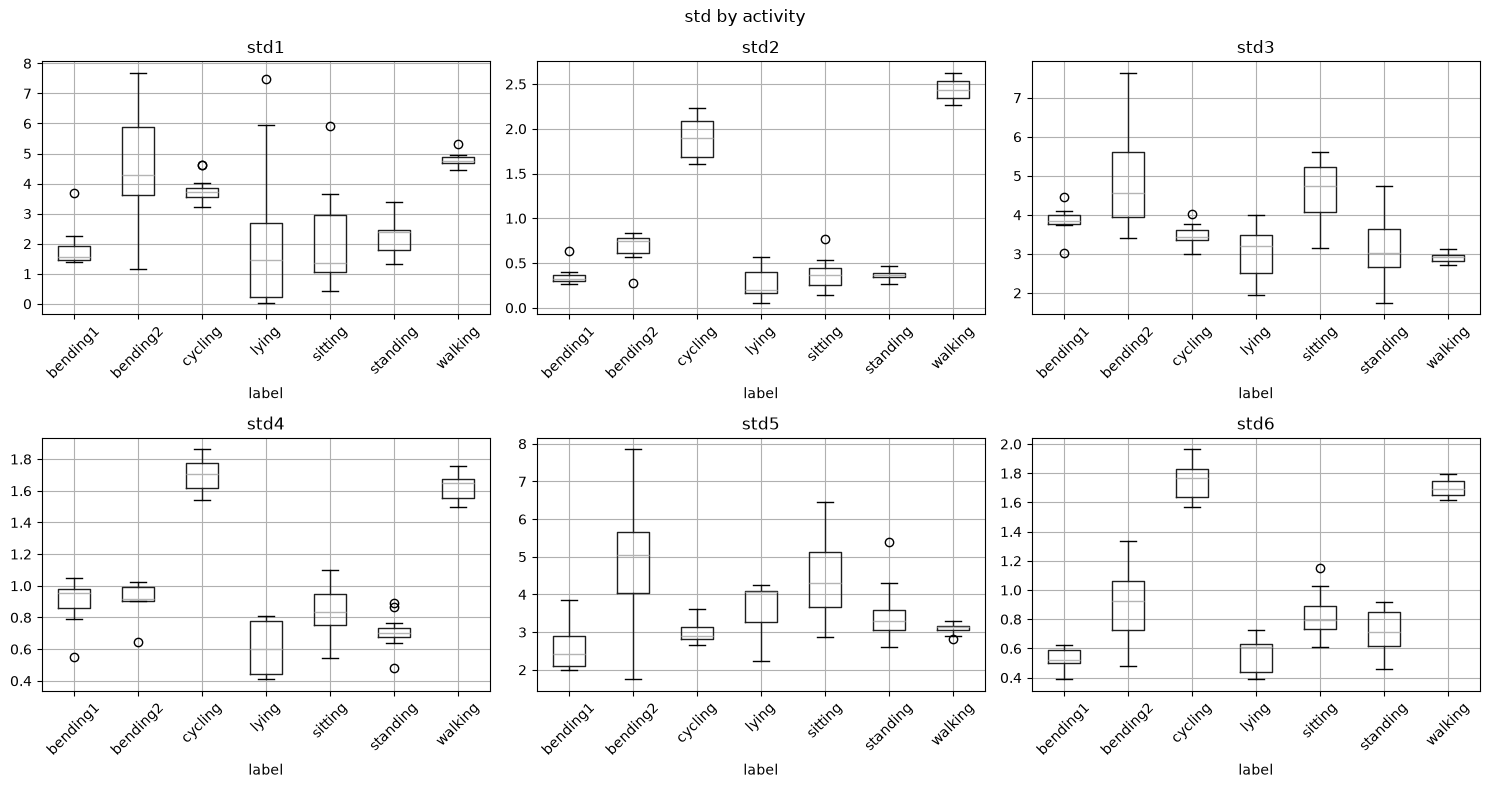

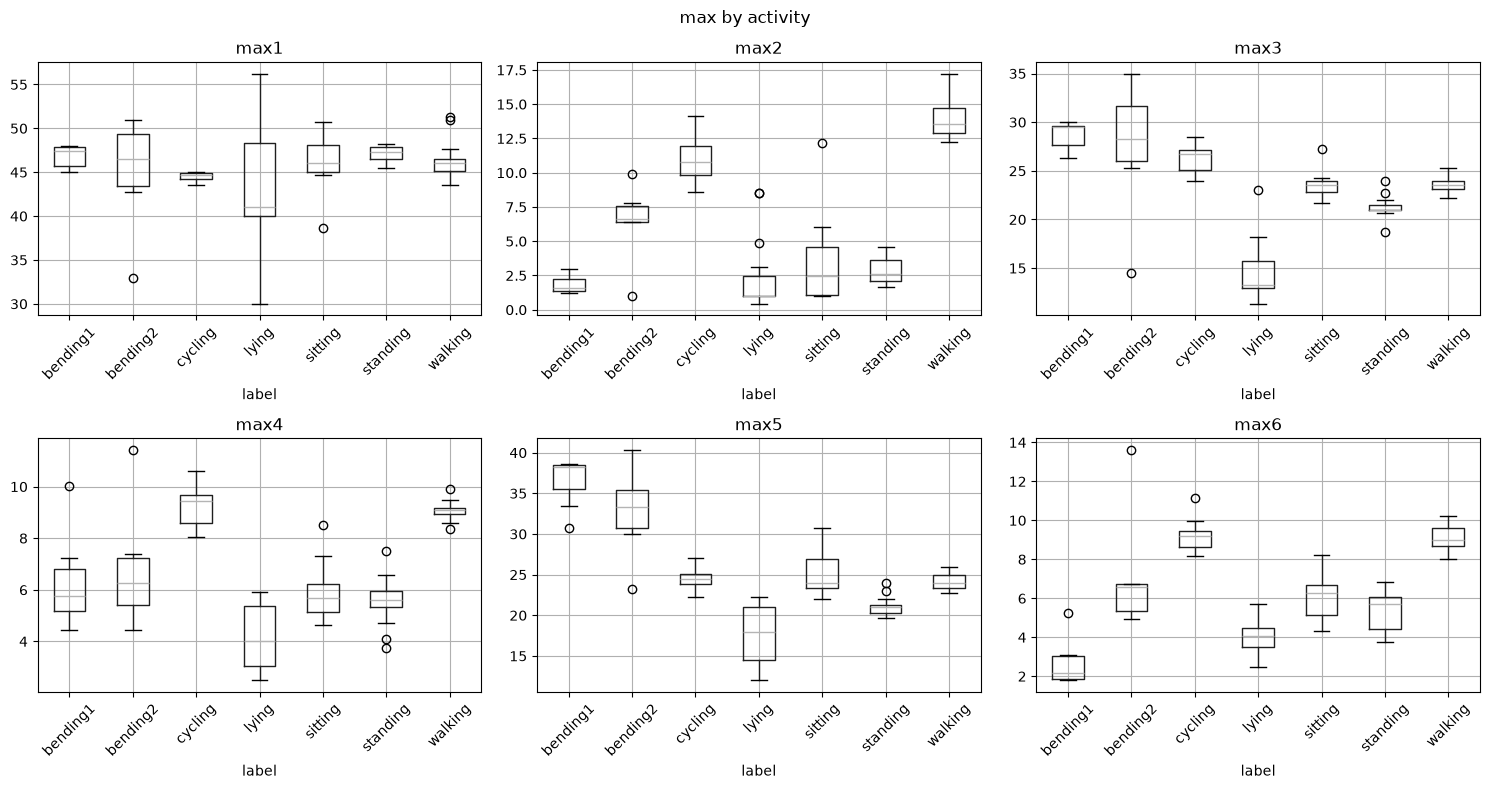

label
cycling     15
lying       15
sitting     15
standing    15
walking     15
bending1     7
bending2     6
Name: count, dtype: int64

In [34]:
for stat in ["mean", "std", "max"]:
    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    for ax, i in zip(axes.flat, range(1, 7)):
        features.boxplot(column=f"{stat}{i}", by="label", ax=ax, rot=45)
        ax.set_title(f"{stat}{i}")
    plt.suptitle(f"{stat} by activity")
    plt.tight_layout()
    plt.show()

features["label"].value_counts()


# stat = "mean"  #std min max
# fig, axes = plt.subplots(2, 3, figsize=(15, 8))
# for ax, i in zip(axes.flat, range(1, 7)):
#     features.boxplot(column=f"{stat}{i}", by="label", ax=ax, rot=45)
#     ax.set_title(f"{stat}{i}")
# plt.suptitle("")
# plt.tight_layout()
# plt.show()

Mean, max, and std as the three most important features.

Mean separates the most classes across the avg and var series 
- mean1: bending2, cycling, and walking in mean1
- mean2/4/6: cycling and walking
 - mean3/5: lying in mean3/5.


Std isolates the moving activities:
- std2/4/6: (cycling and walking in std2/4/6) 
- std3: separates sitting from standing, which are harder to separate in other stats

Max captures spikes
- max2/max6: bending1, bending2, cycling, and walking each sit at different levels
- max3/max5: isolate lying

min was not chosen and was considered weak because it's constant at 0 for series 2, 4, and 6, so there is no useful information there. Median and the quartiles stats separate well but are redundant when considering what mean already shows.

## 2. ISLR 3.7.4

### (a) Linear Train

If the true relationship for X and Y is linear, then the training RSS would be lower for a cubic model since adding more features will allow it more flexibility to fit more  of the noise in the training data. It always causes the training RSS to decrease for cubic or stay the same since cubic can produce the linear fit (with β₂ = β₃ = 0).

### (b) Linear Test

We would expect it would also be larger RSS for cubic than linear, given that the true relationship is linear. the cubic equation is fitting to the training data noise, and since noise is random, it may bend away from it. 

### (c) Not Linear Train

If the true relationship for X and Y is NOT linear, it still holds that the training RSS would be lower for a cubic model compared to a linear model. It always causes the training RSS to decrease for cubic or stay the same since cubic can produce the linear fit (with β₂ = β₃ = 0) and adding more features provides more flexibility to the model to fit noise.

### (d) Not Linear Testing

You would need more information. Since we don't know how far the true relationship is from linear, we are unable to say which model will have smaller test RSS. If the true relationship only slightly nonlinear, the linear model might still do better because the cubic's flexibility mostly fits training noise. But if the truth is strongly nonlinear, the cubic should do better, because the straight line is too rigid to capture the curve. Which effect dominates depends on the true relationship, which is unknown.

## 3. ISLR 3.7.3 - Extra Practice 

## 3. ISLR 3.7.5 - Extra Practice 